In [1]:
import sys
import os
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import at3d
import numpy as np
import matplotlib.pyplot as plt

In [2]:
## Test 00
# iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/tmp/test00/iterations/iter002.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
# sf = 1
# inverse_covariance = sf * np.diag(np.ones(4))
# uncertainty = at3d.uncertainties.Uncertainty(inverse_covariance, 'L2')
# cost_at3d = 0.00013939955825691136

## Test 03
# iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/tmp/test03/iterations/iter002.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
# sf = 10
# inverse_covariance = sf * np.diag(np.ones(4))
# uncertainty = at3d.uncertainties.Uncertainty(inverse_covariance, 'L2')
# cost_at3d = 0.0013939955618910693

## default V00
# iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V00/default/iterations/iter020.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
# uncertainty = at3d.uncertainties.RadiometricNoiseUncertainty(1e-6, 1e-3)
# cost_at3d = 61.492604923369214

## default V01
iterfile = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V01/default/iterations/iter027.nc'
obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
sf = 980e3
inverse_covariance = sf * np.diag(np.ones(4))
uncertainty = at3d.uncertainties.Uncertainty(inverse_covariance, 'L2')
cost_at3d = 63.5349435743488

In [3]:
F_sensor = load_sensor_dict(iterfile)
y_sensor = load_sensor_dict(obs_file)

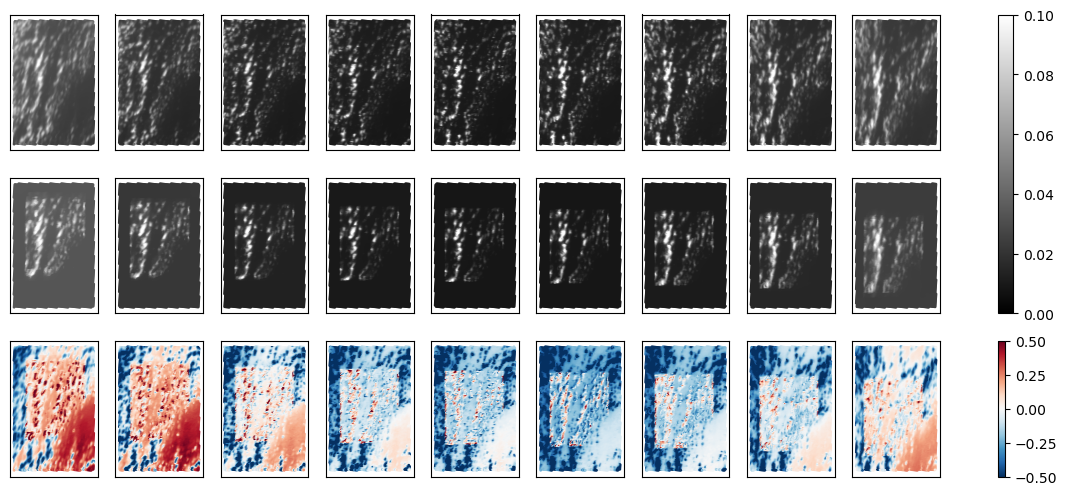

In [4]:
f, ax = plt.subplots(3, 9, figsize=(15, 6))
vmax = 0.1
s = 1
for i in range(9):
    Fs = F_sensor['MISR']['sensor_list'][i]
    ys = y_sensor['MISR']['sensor_list'][i]
    c1 = ax[0,i].scatter(ys.ray_x.data, ys.ray_y.data, c=ys.I.data, s=s, cmap='gray', vmin=0, vmax=vmax)
    c2 = ax[1,i].scatter(Fs.ray_x.data, Fs.ray_y.data, c=Fs.I.data, s=s, cmap='gray', vmin=0, vmax=vmax)
    c3 = ax[2,i].scatter(Fs.ray_x.data, Fs.ray_y.data, c=(Fs.I.data - ys.I.data)/ys.I.data, s=s, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    ax[0,i].set_xticks([])
    ax[0,i].set_yticks([])
    ax[1,i].set_xticks([])
    ax[1,i].set_yticks([])
    ax[2,i].set_xticks([])
    ax[2,i].set_yticks([])
plt.colorbar(c2, ax=ax[0:2, :])
plt.colorbar(c3, ax=ax[2, :])

In [5]:
def obs_vec(sensor, uncertainty):
    vec = np.array([])
    w = np.array([])
    for s in sensor['MISR']['sensor_list']:
        uncertainty.calculate_uncertainties(s)
        vec = np.append(vec, s.I.data)
        Iw = s.isel(num_uncertainty=0, num_uncertainty2=0).uncertainties.data
        w = np.append(w, Iw)
    return vec, w

In [6]:
F, _ = obs_vec(F_sensor, uncertainty)
y, w = obs_vec(y_sensor, uncertainty)

0.26949113435912514


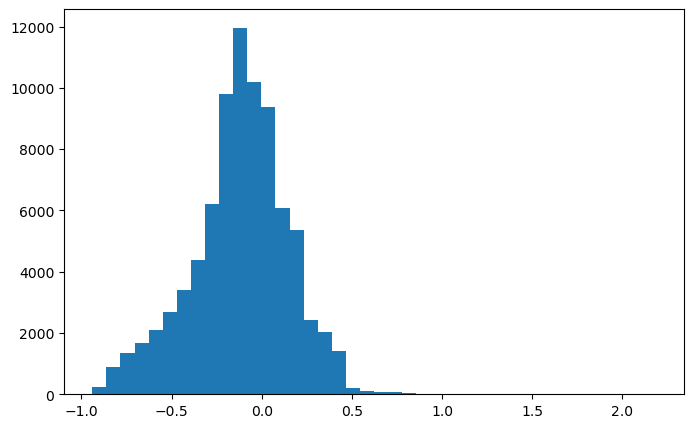

In [7]:
f, ax = plt.subplots(1, 1, figsize=(8, 5))
h = ax.hist((F-y)/y, bins=40)
print(np.std((F-y)/y))

In [8]:
W = np.diag(w)
cost_self = (1/(2*F_sensor.nmeasurements)) * np.matmul(y-F, np.matmul(W, y-F))

In [9]:
print('ME: {}'.format(cost_self))
print('Ans: {}'.format(cost_at3d))
print('Ans - ME: {}'.format(cost_at3d - cost_self))
print('ME / Ans: {}'.format(cost_self/cost_at3d))
print('Ans / Me: {}'.format(cost_at3d/cost_self))

ME: 63.53511981434925
Ans: 63.5349435743488
Ans - ME: -0.00017624000044946797
ME / Ans: 1.000002773906618
Ans / Me: 0.9999972261010767


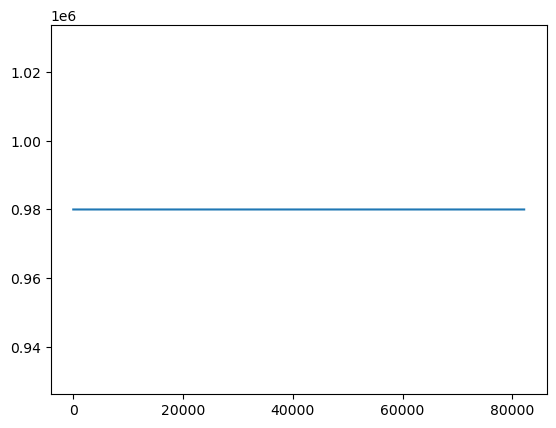

In [10]:
import matplotlib.pyplot as plt

plt.plot(w)